# Experiment 4 — compact feature subset

Tune a LightGBM rent model using only flat type, location, floor area, lease, COE, and stock-market features.

**Executed result:** The selected compact LightGBM run scored RMSE **481.076**, MAE **362.906**, and R² **0.5887** (best iteration 315). Its tuned configuration used depth 5, 25 leaves, 792 requested iterations, learning rate 0.0485, minimum split gain 0.6504, and 16 rows per leaf. This predates the standardized chronological P1 comparison and therefore is not directly ranked against the later AutoGluon experiments.

In [11]:
from pathlib import Path
import os
import sys

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split

RANDOM_STATE = 42
N_TRIALS = 50
TARGET = 'MONTHLY_RENT'

# Supports a local venv, a VS Code kernel, and a Colab runtime where the
# project has been copied or mounted. Set KDDM_PROJECT_ROOT if it lives elsewhere.
configured_root = os.environ.get('KDDM_PROJECT_ROOT')
candidate_roots = ([Path(configured_root)] if configured_root else []) + [
    Path.cwd(), *Path.cwd().parents,
    Path('/content/KDDM-project'),
    Path('/content/drive/MyDrive/KDDM-project'),
]
project_root = next(
    (path for path in candidate_roots if (path / 'exploration/metul/preprocessing.py').exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        'Could not locate the project. Set KDDM_PROJECT_ROOT to the folder containing exploration/metul/preprocessing.py.'
    )

experiment_dir = project_root / 'exploration' / 'metul'
if str(experiment_dir) not in sys.path:
    sys.path.insert(0, str(experiment_dir))

import importlib
import preprocessing
importlib.reload(preprocessing)
from preprocessing import load_datasets, preprocess_frame

sns.set_theme(style='whitegrid', context='notebook')
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [12]:
# Load every source CSV once, then apply the shared train/test feature engineering.
data_dir, datasets = load_datasets()
joined_df = preprocess_frame(datasets['train'], datasets)

FEATURE_COLUMNS = [
    'flat_type_num',
    'TOWN',
    'STREET',
    'BLOCK',
    'FLOOR_AREA_SQM',
    'LEASE_COMMENCE_DATE',
    'coe_quota_premium_mean',
    'stock_close_mean',
    'lease_age',
]
CATEGORICAL_COLUMNS = ['TOWN', 'STREET', 'BLOCK']

missing_features = sorted(set(FEATURE_COLUMNS) - set(joined_df.columns))
if missing_features:
    raise KeyError(f'Missing expected features: {missing_features}')

X = joined_df[FEATURE_COLUMNS].copy()
y = joined_df[TARGET].astype(float).copy()

# Define categories before splitting so validation categories always match training.
for column in CATEGORICAL_COLUMNS:
    values = X[column].fillna('Unknown').astype(str)
    X[column] = pd.Categorical(values, categories=sorted(values.unique()))

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f'Data directory: {data_dir}')
print(f'Train rows: {len(X_train):,} | Validation rows: {len(X_valid):,}')
display(joined_df[FEATURE_COLUMNS + [TARGET]].head())

Data directory: /Users/metul/Desktop/KDDM-project/data
Train rows: 120,000 | Validation rows: 30,000


,flat_type_num,TOWN,STREET,BLOCK,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,coe_quota_premium_mean,stock_close_mean,lease_age,MONTHLY_RENT
0,4,punggol,punggol road,604a,93.0,2012,45187.375,11.662779,9,1800
1,5,sengkang,compassvale crescent,290c,110.0,2001,45187.375,11.662779,20,2000
2,3,queenstown,ghim moh road,5,65.0,1976,45187.375,11.662779,45,2000
3,4,sengkang,fernvale road,436b,96.0,2010,45187.375,11.662779,11,1400
4,4,sembawang,admiralty drive,467b,102.0,2001,45187.375,11.662779,20,1800


In [13]:
def trial_params_to_model_params(params):
    """Translate Optuna names into sklearn LightGBM parameter names."""
    return {
        'objective': 'regression',
        'metric': 'rmse',
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbosity': -1,
        'num_leaves': int(params['num_leaves']),
        'n_estimators': int(params['num_iterations']),
        'learning_rate': float(params['learning_rate']),
        'max_depth': int(params['max_depth']),
        'min_split_gain': float(params['min_gain_to_split']),
        'min_child_samples': int(params['min_data_in_leaf']),
    }

def objective(trial):
    max_depth = trial.suggest_int('max_depth', 3, 12)
    # Restrict leaves to a value feasible for the selected tree depth.
    max_leaves = min(128, 2 ** max_depth)
    params = {
        'num_leaves': trial.suggest_int('num_leaves', 8, max_leaves),
        'num_iterations': trial.suggest_int('num_iterations', 300, 1_800),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'max_depth': max_depth,
        'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0.0, 1.0),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 10, 250),
    }
    model = LGBMRegressor(**trial_params_to_model_params(params))
    model.fit(
        X_train, y_train,
        categorical_feature=CATEGORICAL_COLUMNS,
        eval_set=[(X_valid, y_valid)],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    predictions = model.predict(X_valid, num_iteration=model.best_iteration_)
    return mean_squared_error(y_valid, predictions) ** 0.5

In [14]:
study = optuna.create_study(direction='minimize', study_name='exp_4_feature_subset')
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best_params = study.best_params
best_params_path = experiment_dir / 'exp_4_feature_subset_best_params.csv'
pd.DataFrame([{
    **best_params,
    'best_validation_rmse': study.best_value,
    'feature_count': len(FEATURE_COLUMNS),
    'n_trials': len(study.trials),
}]).to_csv(best_params_path, index=False)

print(f'Best validation RMSE: {study.best_value:,.3f}')
print(f'Best parameters saved to: {best_params_path}')
pd.DataFrame([best_params])

  0%|          | 0/50 [00:00<?, ?it/s]/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 0. Best value: 483.285:   2%|▏         | 1/50 [00:02<02:00,  2.47s/it]/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 1. Best value: 482.226:   4%|▍         | 2/50 [00:05<02:02,  2.54s/it]/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, 

Best validation RMSE: 481.076
Best parameters saved to: /Users/metul/Desktop/KDDM-project/exploration/metul/exp_4_feature_subset_best_params.csv


,max_depth,num_leaves,num_iterations,learning_rate,min_gain_to_split,min_data_in_leaf
0,5,25,792,0.048514,0.650369,16


/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,validation_result
RMSE,481.076479
MAE,362.906459
R2,0.588734
best_iteration,315.000000


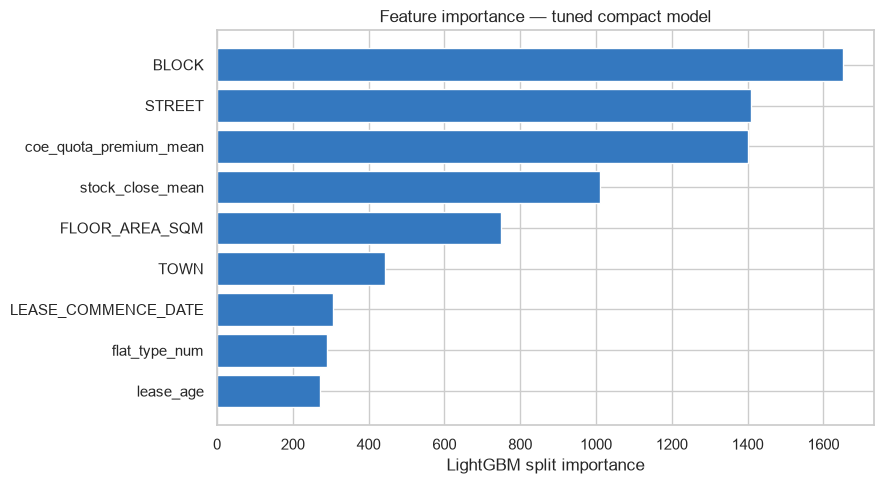

,feature,importance
3,BLOCK,1651
2,STREET,1410
6,coe_quota_premium_mean,1401
7,stock_close_mean,1011
4,FLOOR_AREA_SQM,749
1,TOWN,444
5,LEASE_COMMENCE_DATE,306
0,flat_type_num,289
8,lease_age,272


In [15]:
# Refit with the best settings and report untouched validation predictions.
best_model = LGBMRegressor(**trial_params_to_model_params(best_params))
best_model.fit(
    X_train, y_train,
    categorical_feature=CATEGORICAL_COLUMNS,
    eval_set=[(X_valid, y_valid)],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
valid_predictions = best_model.predict(X_valid, num_iteration=best_model.best_iteration_)

metrics = pd.Series({
    'RMSE': mean_squared_error(y_valid, valid_predictions) ** 0.5,
    'MAE': mean_absolute_error(y_valid, valid_predictions),
    'R2': r2_score(y_valid, valid_predictions),
    'best_iteration': best_model.best_iteration_,
})
display(metrics.to_frame('validation_result'))

importance = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'importance': best_model.feature_importances_,
}).sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance['feature'], importance['importance'], color='#3478bf')
ax.set_title('Feature importance — tuned compact model')
ax.set_xlabel('LightGBM split importance')
plt.tight_layout()
plt.show()
display(importance.sort_values('importance', ascending=False))

In [16]:
# Optional deployment model: train once on all available training rows.
final_model_params = trial_params_to_model_params(best_params)
final_model_params['n_estimators'] = best_model.best_iteration_ or best_params['num_iterations']
final_model = LGBMRegressor(**final_model_params)
final_model.fit(X, y, categorical_feature=CATEGORICAL_COLUMNS)
print(f'Final model fitted on {len(X):,} rows using {len(FEATURE_COLUMNS)} features.')

Final model fitted on 150,000 rows using 9 features.


## Cross-validation — COE versus individual stock prices

This experiment retains `BLOCK`, `STREET`, `FLOOR_AREA_SQM`, and the COE premium as the previous feature set, then adds only the five most important individual stock-price features. Stock importance is measured with cross-validated LightGBM split importance before the second Optuna tuning stage.

In [17]:
# Create one monthly average close-price column per stock symbol.
stock = datasets['stock'].copy()
stock['DATE'] = pd.to_datetime(stock['DATE'])
stock['approval_year'] = stock['DATE'].dt.year
stock['approval_month'] = stock['DATE'].dt.month

monthly_stock_by_symbol = (
    stock.groupby(['approval_year', 'approval_month', 'SYMBOL'])['CLOSE']
    .mean()
    .unstack('SYMBOL')
    .add_prefix('stock_close_')
    .reset_index()
)

CV_BASE_FEATURES = [
    'BLOCK', 'STREET', 'FLOOR_AREA_SQM', 'coe_quota_premium_mean',
]
STOCK_FEATURES = [
    column for column in monthly_stock_by_symbol.columns
    if column.startswith('stock_close_')
]

cv_df = joined_df[
    ['approval_year', 'approval_month', TARGET, *CV_BASE_FEATURES]
].merge(
    monthly_stock_by_symbol, on=['approval_year', 'approval_month'], how='left'
)

print(f'Individual stock columns: {len(STOCK_FEATURES)}')
display(pd.DataFrame({
    'feature': STOCK_FEATURES,
    'non_null_rows': [cv_df[column].notna().sum() for column in STOCK_FEATURES],
}).sort_values('feature').reset_index(drop=True))

Individual stock columns: 77


,feature,non_null_rows
0,stock_close_0799.HK,150000
1,stock_close_1792.HK,150000
2,stock_close_2588.HK,150000
3,stock_close_5E2.SI,150000
4,stock_close_9658.HK,82506
...,...,...
72,stock_close_VC2.SI,150000
73,stock_close_WBUY,53135
74,stock_close_WVE,150000
75,stock_close_Z25.SI,150000


In [18]:
def prepare_cv_features(frame, feature_columns):
    result = frame[feature_columns].copy()
    for column in ['BLOCK', 'STREET']:
        values = result[column].fillna('Unknown').astype(str)
        result[column] = pd.Categorical(values, categories=sorted(values.unique()))
    return result

def run_lgbm_cv(frame, feature_columns, model_params, n_splits=5):
    """Return OOF predictions, RMSE, and mean split importance across folds."""
    features = prepare_cv_features(frame, feature_columns)
    target = frame[TARGET].astype(float).to_numpy()
    oof_predictions = np.zeros(len(frame))
    fold_scores = []
    importances = np.zeros(len(feature_columns))
    folds = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

    for fold, (train_idx, valid_idx) in enumerate(folds.split(features), start=1):
        model = LGBMRegressor(**model_params)
        model.fit(
            features.iloc[train_idx], target[train_idx],
            categorical_feature=['BLOCK', 'STREET'],
        )
        fold_predictions = model.predict(features.iloc[valid_idx])
        oof_predictions[valid_idx] = fold_predictions
        fold_rmse = mean_squared_error(target[valid_idx], fold_predictions) ** 0.5
        fold_scores.append(fold_rmse)
        importances += model.feature_importances_
        print(f'Fold {fold}: RMSE = {fold_rmse:,.3f}')

    return {
        'oof_predictions': oof_predictions,
        'overall_rmse': mean_squared_error(target, oof_predictions) ** 0.5,
        'fold_scores': fold_scores,
        'importance': pd.DataFrame({
            'feature': feature_columns,
            'importance': importances / n_splits,
        }).sort_values('importance', ascending=False),
    }

# Reuse the tuned parameters from the preceding section and its selected number of trees.
cv_model_params = trial_params_to_model_params(best_params)
cv_model_params['n_estimators'] = int(best_model.best_iteration_ or best_params['num_iterations'])

coe_baseline_cv = run_lgbm_cv(cv_df, CV_BASE_FEATURES, cv_model_params)
individual_stock_cv = run_lgbm_cv(
    cv_df, CV_BASE_FEATURES + STOCK_FEATURES, cv_model_params
)

cv_comparison = pd.DataFrame([
    {
        'model': 'COE + block/street/floor area',
        'feature_count': len(CV_BASE_FEATURES),
        'overall_oof_rmse': coe_baseline_cv['overall_rmse'],
        'mean_fold_rmse': np.mean(coe_baseline_cv['fold_scores']),
        'std_fold_rmse': np.std(coe_baseline_cv['fold_scores']),
    },
    {
        'model': 'COE + individual stocks + block/street/floor area',
        'feature_count': len(CV_BASE_FEATURES + STOCK_FEATURES),
        'overall_oof_rmse': individual_stock_cv['overall_rmse'],
        'mean_fold_rmse': np.mean(individual_stock_cv['fold_scores']),
        'std_fold_rmse': np.std(individual_stock_cv['fold_scores']),
    },
]).sort_values('overall_oof_rmse').reset_index(drop=True)

display(cv_comparison.style.format({
    'overall_oof_rmse': '{:,.3f}',
    'mean_fold_rmse': '{:,.3f}',
    'std_fold_rmse': '{:,.3f}',
}))

Fold 1: RMSE = 488.688
Fold 2: RMSE = 490.193
Fold 3: RMSE = 487.846
Fold 4: RMSE = 488.212
Fold 5: RMSE = 489.308
Fold 1: RMSE = 484.981
Fold 2: RMSE = 487.266
Fold 3: RMSE = 485.584
Fold 4: RMSE = 485.547
Fold 5: RMSE = 485.818


,model,feature_count,overall_oof_rmse,mean_fold_rmse,std_fold_rmse
0,COE + individual stocks + block/street/floor area,81,485.840,485.840,0.765
1,COE + block/street/floor area,4,488.850,488.850,0.831


Top 5 stock features selected by CV importance:


,feature,importance
0,stock_close_0799.HK,126.8
1,stock_close_C07.SI,112.4
2,stock_close_9658.HK,95.0
3,stock_close_C52.SI,94.2
4,stock_close_BTDR,88.6


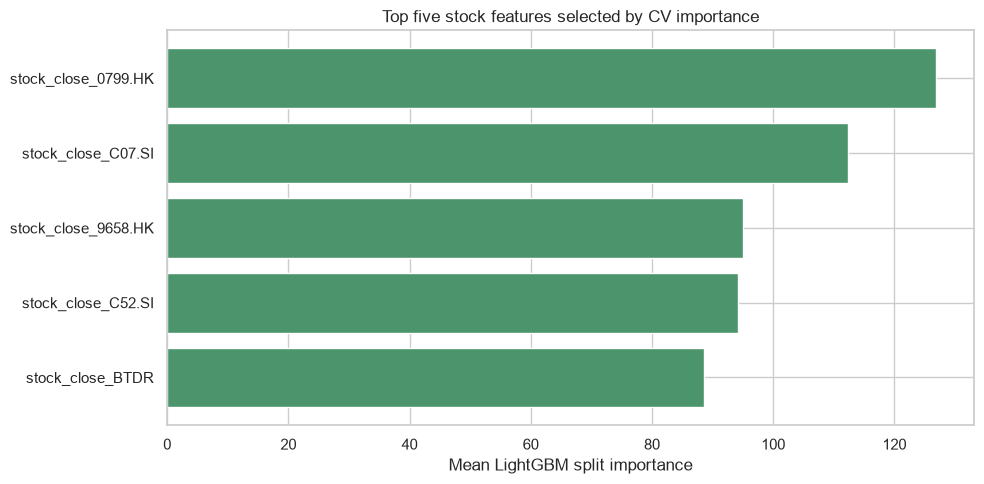

  0%|          | 0/50 [00:00<?, ?it/s]/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 0. Best value: 486.347:   2%|▏         | 1/50 [00:02<02:25,  2.98s/it]/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 1. Best value: 485.363:   4%|▍         | 2/50 [00:04<01:48,  2.26s/it]/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, 

Top-5-stock HPT best RMSE: 485.214
Features tuned: ['BLOCK', 'STREET', 'FLOOR_AREA_SQM', 'coe_quota_premium_mean', 'stock_close_0799.HK', 'stock_close_C07.SI', 'stock_close_9658.HK', 'stock_close_C52.SI', 'stock_close_BTDR']
Best parameters saved to: /Users/metul/Desktop/KDDM-project/exploration/metul/exp_4_top_5_stocks_best_params.csv


,max_depth,num_leaves,num_iterations,learning_rate,min_gain_to_split,min_data_in_leaf
0,3,8,1154,0.04472,0.640673,50


In [19]:
# Rank individual stocks by mean cross-validated split importance.
stock_importance = individual_stock_cv['importance'].loc[
    individual_stock_cv['importance']['feature'].str.startswith('stock_close_')
].reset_index(drop=True)
TOP_N_STOCKS = 5
TOP_STOCK_FEATURES = stock_importance.head(TOP_N_STOCKS)['feature'].tolist()
SELECTED_FEATURES = CV_BASE_FEATURES + TOP_STOCK_FEATURES

print(f'Top {TOP_N_STOCKS} stock features selected by CV importance:')
display(stock_importance.head(TOP_N_STOCKS))

fig, ax = plt.subplots(figsize=(10, 5))
top_stock_plot = stock_importance.head(TOP_N_STOCKS).sort_values('importance')
ax.barh(top_stock_plot['feature'], top_stock_plot['importance'], color='#4c956c')
ax.set_title('Top five stock features selected by CV importance')
ax.set_xlabel('Mean LightGBM split importance')
plt.tight_layout()
plt.show()

# Fresh HPT for the previous feature set plus the selected five stocks.
X_hpt = cv_df[SELECTED_FEATURES].copy()
y_hpt = cv_df[TARGET].astype(float).copy()
for column in ['BLOCK', 'STREET']:
    values = X_hpt[column].fillna('Unknown').astype(str)
    X_hpt[column] = pd.Categorical(values, categories=sorted(values.unique()))
X_hpt_train, X_hpt_valid, y_hpt_train, y_hpt_valid = train_test_split(
    X_hpt, y_hpt, test_size=0.20, random_state=RANDOM_STATE
)

def stock_hpt_objective(trial):
    max_depth = trial.suggest_int('max_depth', 3, 12)
    params = {
        'num_leaves': trial.suggest_int('num_leaves', 8, min(128, 2 ** max_depth)),
        'num_iterations': trial.suggest_int('num_iterations', 300, 1_800),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'max_depth': max_depth,
        'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0.0, 1.0),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 10, 250),
    }
    model = LGBMRegressor(**trial_params_to_model_params(params))
    model.fit(
        X_hpt_train, y_hpt_train, categorical_feature=['BLOCK', 'STREET'],
        eval_set=[(X_hpt_valid, y_hpt_valid)],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    predictions = model.predict(X_hpt_valid, num_iteration=model.best_iteration_)
    return mean_squared_error(y_hpt_valid, predictions) ** 0.5

stock_study = optuna.create_study(
    direction='minimize', study_name='exp_4_top_5_stocks',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
stock_study.optimize(stock_hpt_objective, n_trials=N_TRIALS, show_progress_bar=True)
stock_best_params = stock_study.best_params
stock_best_params_path = experiment_dir / 'exp_4_top_5_stocks_best_params.csv'
pd.DataFrame([{
    **stock_best_params,
    'best_validation_rmse': stock_study.best_value,
    'feature_count': len(SELECTED_FEATURES),
    'selected_stock_features': ','.join(TOP_STOCK_FEATURES),
    'n_trials': len(stock_study.trials),
}]).to_csv(stock_best_params_path, index=False)

print(f'Top-5-stock HPT best RMSE: {stock_study.best_value:,.3f}')
print(f'Features tuned: {SELECTED_FEATURES}')
print(f'Best parameters saved to: {stock_best_params_path}')
display(pd.DataFrame([stock_best_params]))